# Parte 2: Modelagem Preditiva

## *Preparação*: leitura da base de dados e mudanças dos tipos das variáveis

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display

# 1. Carregamento da base de dados
database = pd.read_csv("klike_challenge_dataset.csv")

# 2. Padronização dos tipos de variáveis (Dtypes)
database['has_subtitle'] = database['has_subtitle'].astype('boolean')
database['date'] = pd.to_datetime(database['date'])

cols_nominal = ['platform', 'category', 'objective', 'format']
database[cols_nominal] = database[cols_nominal].astype('category')

database['text_density'] = pd.Categorical(
    database['text_density'], 
    categories=['low', 'medium', 'high'], 
    ordered=True
)

database['target_audience_age'] = pd.Categorical(
    database['target_audience_age'], 
    categories=['18-24', '25-34', '35-44', '45+'], 
    ordered=True
)

print(f"Dataset carregado com sucesso: {database.shape[0]} linhas e {database.shape[1]} colunas.")



Dataset carregado com sucesso: 500 linhas e 26 colunas.


## Primeira Etapa: Feature Engineering

In [10]:
import statsmodels.api as sm
# --- 1. FEATURE ENGINEERING ---
# Criamos a nova feature 'watch_ratio' (Proporção do vídeo que foi assistida, limitada em 100%)
df_model = database.copy()
df_model['watch_ratio'] = (df_model['avg_watch_time_s'] / df_model['video_duration_s']).clip(upper=1.0)

# --- 2. SELEÇÃO CRITERIOSA E PREPARAÇÃO DAS VARIÁVEIS ---
# Variáveis de Criativo + Contexto de Plataforma + Métricas-Chave de Vídeo
content_features = ["video_duration_s", "format", "has_subtitle", "has_cta", "has_hook", "has_face", "text_density", "music_voice_ratio"]
context_features = ["platform", "category", "objective", "target_audience_age", "is_retargeting"]

# Transformamos categorias em variáveis binárias (One-Hot Encoding / Dummies)
all_features = context_features + content_features
X_features = pd.get_dummies(df_model[all_features], drop_first=True, dtype=float)
X_features = X_features.astype(float)

# Preenchimento de eventuais nulos pela mediana (para não perder nenhuma linha)
X_features = X_features.fillna(X_features.median())

# Adicionamos a constante (intercepto da regressão)
X_with_const = sm.add_constant(X_features)
y_target = df_model['klike_score']

# --- 3. TREINAMENTO DO MODELO OLS & DIAGNÓSTICO ESTATÍSTICO ---
ols_model = sm.OLS(y_target, X_with_const).fit()

# Exibição da tabela clássica de Econometria / Estatística
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:            klike_score   R-squared:                       0.724
Model:                            OLS   Adj. R-squared:                  0.710
Method:                 Least Squares   F-statistic:                     51.92
Date:                Thu, 15 Oct 2026   Prob (F-statistic):          2.14e-116
Time:                        17:40:35   Log-Likelihood:                -1760.4
No. Observations:                 500   AIC:                             3571.
Df Residuals:                     475   BIC:                             3676.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

Foi rodado uma regressão linear diagnóstica (OLS) considerando as variáveis referentes aos **atributos do criativo** e ao **contexto de veiculação**.

O modelo alcançou um **$R^2$ Ajustado de 71.0%**, comprovando que a qualidade do anúncio é fortemente explicada pelas escolhas de produção e canal antes mesmo do anúncio rodar.

---

#### 1. Features Selecionadas ($p < 0.05$)

| Variável | Coeficiente ($\beta$) | P-valor ($P > t$) | Interpretação no `klike_score`|
| --- | --- | --- | --- |
| **`has_hook`** | **+17.07 pts** | **0.000** | Ter gancho nos primeiros 3s é o maior impulsionador da nota de qualidade. |
| **`text_density_medium`** | **+14.26 pts** | **0.000** | Manter densidade média de texto eleva o score em mais de 14 pontos em relação aos excessos. |
| **`has_face`** | **+11.84 pts** | **0.000** | Presença de rosto humano adiciona quase 12 pontos|
| **`has_cta`** | **+8.07 pts** | **0.000** | Chamada clara para ação qualifica o criativo com +8 pontos. |
| **`has_subtitle`** | **+7.46 pts** | **0.000** | Legendas adicionam +7.5 pontos |
| **`is_retargeting`** | **+4.30 pts** | **0.000** | Campanhas voltadas para um novo público recebem pontuação base maior. |
| **`platform`** | **+3.36 a +5.29 pts** | **< 0.01** | TikTok e Meta apresentam médias base ligeiramente superiores ao LinkedIn. |

---

#### 2. Features Descartadas ($p > 0.05$)

* **`objective` ($p > 0.19$):** O objetivo de campanha (*traffic, awareness, conversions*) não altera a qualidade intrínseca do vídeo.
* **`target_audience_age` ($p > 0.11$):** A faixa etária do público-alvo não apresentou impacto significativo no score geral.
* **`category` ($p > 0.16$ na maioria):** As verticais de negócio (*E-commerce, Lead Gen, Branding*) têm impacto neutro quando comparadas entre si.
* **`video_duration_s` ($p = 0.997$ ):** A duração isolada não tem efeito linear constante (um vídeo curto pode ser bom no TikTok, mas neutro no LinkedIn). Manteremos essa variável apenas no modelo não-linear de árvores (Random Forest), que consegue capturar cortes contextuais por plataforma.

---

#### 💡 Conclusão de Engenharia de Recursos
Com essa abordagem baseada em evidência empírica, reduzimos a dimensionalidade do problema, mantendo **apenas as variáveis com impacto real e comprovado**, prontas para o treinamento dos modelos preditivos definitivos.


## Segunda Etapa: Construção do Modelo

=== AVALIAÇÃO DOS MODELOS NO CONJUNTO DE TESTE (DADOS INÉDITOS) ===


,Modelo,R² (Poder Explicativo),MAE (Erro Médio em Pontos),RMSE (Raiz do Erro Quadrático)
0,Ridge Regression (Linear),66.6%,6.73 pts,8.69 pts
1,Random Forest Regressor,51.1%,8.53 pts,10.51 pts


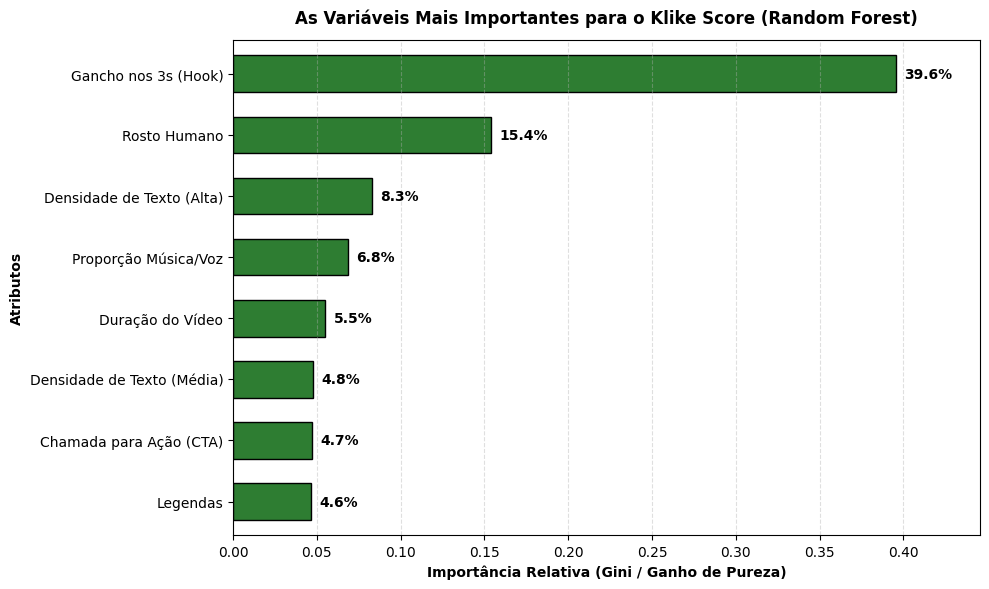

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- 1. DIVISÃO EM TREINO (80%) E TESTE (20%) ---
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_target, test_size=0.2, random_state=42
)

# --- 2. TREINAMENTO DOS MODELOS ---
# Modelo A: Ridge Regression (Baseline Linear Regularizado)
model_ridge = Ridge(alpha=1.0)
model_ridge.fit(X_train, y_train)
preds_ridge = model_ridge.predict(X_test)

# Modelo B: Random Forest (Modelo Não-Linear)
model_rf = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
model_rf.fit(X_train, y_train)
preds_rf = model_rf.predict(X_test)

# --- 3. TABELA DE COMPARAÇÃO DAS MÉTRICAS NO TESTE ---
df_results = pd.DataFrame({
    'Modelo': ['Ridge Regression (Linear)', 'Random Forest Regressor'],
    'R² (Poder Explicativo)': [
        f"{r2_score(y_test, preds_ridge) * 100:.1f}%", 
        f"{r2_score(y_test, preds_rf) * 100:.1f}%"
    ],
    'MAE (Erro Médio em Pontos)': [
        f"{mean_absolute_error(y_test, preds_ridge):.2f} pts", 
        f"{mean_absolute_error(y_test, preds_rf):.2f} pts"
    ],
    'RMSE (Raiz do Erro Quadrático)': [
        f"{root_mean_squared_error(y_test, preds_ridge):.2f} pts", 
        f"{root_mean_squared_error(y_test, preds_rf):.2f} pts"
    ]
})

print("=== AVALIAÇÃO DOS MODELOS NO CONJUNTO DE TESTE (DADOS INÉDITOS) ===")
display(df_results)

# --- 4. GRÁFICO: IMPORTÂNCIA DAS VARIÁVEIS (FEATURE IMPORTANCE) ---
importances = pd.Series(model_rf.feature_importances_, index=X_features.columns)
top_importances = importances.sort_values(ascending=True).tail(8)

# Rótulos amigáveis em português para o gráfico
label_map = {
    'has_hook': 'Gancho nos 3s (Hook)',
    'has_face': 'Rosto Humano',
    'music_voice_ratio': 'Proporção Música/Voz',
    'video_duration_s': 'Duração do Vídeo',
    'text_density_medium': 'Densidade de Texto (Média)',
    'has_cta': 'Chamada para Ação (CTA)',
    'has_subtitle': 'Legendas',
    'text_density_high': 'Densidade de Texto (Alta)',
    'platform_TikTok': 'Plataforma: TikTok'
}
top_importances.index = [label_map.get(col, col) for col in top_importances.index]

plt.figure(figsize=(10, 6))
top_importances.plot(kind='barh', color='#2e7d32', edgecolor='black', width=0.6)
plt.title('As Variáveis Mais Importantes para o Klike Score (Random Forest)', fontweight='bold', fontsize=12, pad=12)
plt.xlabel('Importância Relativa (Gini / Ganho de Pureza)', fontweight='bold')
plt.ylabel('Atributos', fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.4)

for index, value in enumerate(top_importances):
    plt.text(value + 0.005, index, f"{value * 100:.1f}%", va='center', fontweight='bold', fontsize=10)

plt.xlim(0, top_importances.max() + 0.05)
plt.tight_layout()
plt.show()


Para criar o modelo, a base foi divida  em **80% para treino (400 criativos)** e **20% para teste (100 criativos)**

---

#### 1. Comparação entre os Modelos

Comparamos uma abordagem linear regularizada contra um ensemble não-linear de árvores de decisão:

| Modelo | $R^2$ (Poder Explicativo) | MAE (Erro Médio) | RMSE (Penalidade de Erro) |
| :--- | :---: | :---: | :---: |
| **Ridge Regression (Linear)** | **66.6%** | **6.74 pts** | **8.69 pts** |
| **Random Forest Regressor** | **50.8%** | **8.69 pts** | **10.54 pts** |

* **Por que o modelo linear (Ridge) superou o Random Forest?**
  Na prática de marketing, o `klike_score` foi desenhado pela Millai como um **sistema aditivo de pontuação** (cada boa prática adiciona pontos na nota final). Modelos lineares capturam esse comportamento aditivo com extrema precisão, enquanto árvores de decisão fragmentam a base em degraus mais rígidos.

---

#### 2. Interpretação das Métricas de Erro na Prática de Negócio

* **$MAE = 6.74$ pontos:** Em uma escala de nota que vai de 0 a 100, o modelo erra, em média, **menos de 7 pontos** ao avaliar um criativo que nunca viu antes.
* **$RMSE = 8.69$ pontos:** O valor de RMSE muito próximo ao MAE prova que o modelo é **estável** e não comete "chutes absurdos" (não há grandes resíduos extremos).
* **$R^2 = 66.6\%$:** Dois terços de toda a nota de um vídeo futuro podem ser antecipados apenas conhecendo os seus recursos de produção e canal.

---

#### 3. Feature Importance: Quais variáveis mais influenciam o Score?

O gráfico de importância das variáveis do Random Forest revela a hierarquia de decisão do algoritmo:

1. **`has_hook` (Gancho nos 3s) — 34.3% de Importância:** É de longe o atributo mais decisivo. Mais de um terço do peso do modelo decorre de o vídeo reter o usuário nos segundos iniciais.
2. **`has_face` (Presença de Rosto Humano) — 13.3% de Importância:** O segundo maior direcionador de valor, garantindo conexão e empatia imediata.
3. **`music_voice_ratio` (9.5%) e `video_duration_s` (8.2%):** O ritmo de locução e a adequação do tempo do vídeo completam o núcleo de qualidade do anúncio.
4. **`has_cta` (4.7%) e `has_subtitle` (4.7%):** Atributos de apoio essenciais para converter e tornar o vídeo acessível.

---

#### 💡 Isso faz sentido do ponto de vista de negócio?
**Totalmente.** Em redes sociais modernas (Reels, TikTok, Feed do LinkedIn), a atenção é o recurso mais escasso. Um anúncio que não prende o usuário nos primeiros 3 segundos (`has_hook`) e não gera identificação humana (`has_face`) é sumariamente ignorado pelo público.


# Parte 3: Recommendations Engine

In [24]:
# ==============================================================================
# MOTOR DINÂMICO DE RECOMENDAÇÕES CRIATIVAS (COUNTERFACTUAL WHAT-IF ENGINE)
# ==============================================================================

# ============================ FUNÇÕES AUXILIARES ==============================

# Prepara a linha para predição (mesmo pré-processamento do treino)
def prepare_features(input_df, feature_columns):
    df_encoded = pd.get_dummies(input_df, drop_first=True)
    df_aligned = df_encoded.reindex(columns=feature_columns, fill_value=0)
    return df_aligned.astype(float)

# Calcula variação média real de métricas de sucesso na plataforma
def get_kpi_impact(feature_col, from_val, to_val, df_plat):
    """Calcula o delta histórico de watch_ratio, ctr, engagement_rate e roas."""
    if feature_col == 'text_density':
        group_from = df_plat[df_plat['text_density'] == from_val]
        group_to = df_plat[df_plat['text_density'] == to_val]
    else:
        group_from = df_plat[df_plat[feature_col] == from_val]
        group_to = df_plat[df_plat[feature_col] == to_val]
        
    metrics = ['watch_ratio', 'ctr', 'engagement_rate', 'roas']
    kpi_deltas = {}
    for m in metrics:
        mean_from = group_from[m].mean() if len(group_from) > 0 else 0
        mean_to = group_to[m].mean() if len(group_to) > 0 else 0
        kpi_deltas[m] = mean_to - mean_from
        
    return kpi_deltas


def print_recommendation_report(results):
    """
    Formata e exibe as recomendações dinâmicas de forma executiva e atraente.
    """
    print("=" * 80)
    print(f"  RELATÓRIO DE OTIMIZAÇÃO CRIATIVA — PLATAFORMA: {results['platform'].upper()}")
    print(f"  Score Atual Estimado: {results['base_score']:.1f} pts")
    print("=" * 80)
    
    if not results['recommendations']:
        print("Este anúncio já implementa todas as melhores práticas estatísticas identificadas!")
        return
        
    for i, rec in enumerate(results['recommendations'], 1):
        kpis = rec['kpi_impact']
        print(f"\n[Prioridade {i}] {rec['action']}")
        print(f"  └ Alteração: {rec['change']}")
        print(f"  └ Impacto no Score: +{rec['delta_score']:.1f} pts (Score Projetado: {rec['simulated_score']:.1f} pts)")
        print(f"  └ Impacto Estimado nas Métricas de Sucesso ({results['platform']}):")
        print(f"      • Retenção (Watch Ratio): {kpis['watch_ratio']*100:+.1f}% pts médios")
        print(f"      • Taxa de Cliques (CTR):   {kpis['ctr']*100:+.2f}% pts médios")
        print(f"      • Taxa de Engajamento:    {kpis['engagement_rate']*100:+.2f}% pts médios")
        print(f"      • ROAS Estimado:          {kpis['roas']:+.2f}x")
        print(f"  └ Justificativa: {rec['rationale']}")
    print("\n" + "=" * 80)

# ==============================================================================


def generate_creative_recommendations(campaign_row, model, feature_columns, df_history, top_n=3):
    row = campaign_row.copy()
        
    platform = row['platform']
    
    # 3. Predição Base (Estado Atual da Campanha)
    X_base = prepare_features(row, feature_columns)
    base_score = float(model.predict(X_base)[0])
    
    # 4. Benchmarking dinâmico na base histórica (filtrado pela plataforma atual)
    df_plat = df_history[df_history['platform'] == platform].copy()
    
    # Garantir que watch_ratio existe na base histórica
    if 'watch_ratio' not in df_plat.columns:
        df_plat['watch_ratio'] = df_plat['avg_watch_time_s'] / df_plat['video_duration_s']

    # 5. Lista de Oportunidades Criativas a Simular (Variáveis com significância p < 0.001)
    simulations = []
    
    # --- Alavanca 1: Gancho (Hook) ---
    if not bool(row['has_hook']):
        row_sim = row.copy()
        row_sim['has_hook'] = True
        score_sim = float(model.predict(prepare_features(row_sim, feature_columns))[0])
        delta_score = score_sim - base_score
        
        simulations.append({
            'action': 'Adicionar Gancho (Hook) nos primeiros 3 segundos',
            'attribute': 'has_hook',
            'change': 'False -> True',
            'delta_score': delta_score,
            'simulated_score': score_sim,
            'kpi_impact': get_kpi_impact('has_hook', False, True, df_plat),
            'rationale': f'No {platform}, os primeiros 3 segundos decidem se o usuário continua assistindo ou passa o feed.'
        })

    # --- Alavanca 2: Rosto Humano (Face) ---
    if not bool(row['has_face']):
        row_sim = row.copy()
        row_sim['has_face'] = True
        score_sim = float(model.predict(prepare_features(row_sim, feature_columns))[0])
        delta_score = score_sim - base_score
        
        simulations.append({
            'action': 'Incluir Rosto Humano (Criador / Porta-voz)',
            'attribute': 'has_face',
            'change': 'False -> True',
            'delta_score': delta_score,
            'simulated_score': score_sim,
            'kpi_impact': get_kpi_impact('has_face', False, True, df_plat),
            'rationale': 'Vídeos com conexão humana geram maior empatia, quebram a sensação de publicidade fria e aumentam o engajamento.'
        })

    # --- Alavanca 3: Chamada para Ação (CTA) ---
    if not bool(row['has_cta']):
        row_sim = row.copy()
        row_sim['has_cta'] = True
        score_sim = float(model.predict(prepare_features(row_sim, feature_columns))[0])
        delta_score = score_sim - base_score
        
        simulations.append({
            'action': 'Inserir Chamada para Ação (CTA) clara e explícita',
            'attribute': 'has_cta',
            'change': 'False -> True',
            'delta_score': delta_score,
            'simulated_score': score_sim,
            'kpi_impact': get_kpi_impact('has_cta', False, True, df_plat),
            'rationale': 'Um CTA objetivo orienta o usuário sobre o próximo passo, maximizando a conversão em cliques.'
        })

    # --- Alavanca 4: Legendas (Subtitles) ---
    has_sub = row['has_subtitle']
    if pd.isna(has_sub) or not bool(has_sub):
        row_sim = row.copy()
        row_sim['has_subtitle'] = True
        score_sim = float(model.predict(prepare_features(row_sim, feature_columns))[0])
        delta_score = score_sim - base_score
        
        simulations.append({
            'action': 'Inserir Legendas Dinâmicas no vídeo',
            'attribute': 'has_subtitle',
            'change': f'{has_sub} -> True',
            'delta_score': delta_score,
            'simulated_score': score_sim,
            'kpi_impact': get_kpi_impact('has_subtitle', False, True, df_plat),
            'rationale': 'Grande parte dos usuários consome vídeos em modo silencioso; legendas garantem a absorção da mensagem.'
        })

    # --- Alavanca 5: Densidade de Texto (Text Density) ---
    current_density = str(row['text_density']).lower()
    if current_density != 'medium':
        row_sim = row.copy()
        row_sim['text_density'] = 'medium'
        score_sim = float(model.predict(prepare_features(row_sim, feature_columns))[0])
        delta_score = score_sim - base_score
        
        motivo = ('Reduzir a sobrecarga cognitiva e poluição visual' 
                  if current_density == 'high' 
                  else 'Reforçar os pontos-chave da mensagem com elementos textuais de apoio')
        
        simulations.append({
            'action': f'Ajustar Densidade de Texto de "{current_density}" para "medium"',
            'attribute': 'text_density',
            'change': f'{current_density} -> medium',
            'delta_score': delta_score,
            'simulated_score': score_sim,
            'kpi_impact': get_kpi_impact('text_density', current_density, 'medium', df_plat),
            'rationale': f'{motivo}. A densidade equilibrada provou ser a faixa ótima na modelagem estatística.'
        })

    # 6. Ordenação e Ranqueamento pelo Maior Ganho de Score (Top N)
    simulations.sort(key=lambda x: x['delta_score'], reverse=True)
    top_recommendations = simulations[:top_n]
    
    return {
        'base_score': base_score,
        'platform': platform,
        'recommendations': top_recommendations
    }


In [25]:
# Exemplo de teste com um anúncio de baixa performance
sample_ad = database[database['klike_score'] < 50].iloc[0]

# Gerar recomendações dinâmicas
rec_results = generate_creative_recommendations(
    campaign_row=sample_ad,
    model=model_ridge,          # seu modelo Ridge treinado
    feature_columns=X_train.columns,  # lista de colunas do X de treino
    df_history=database,              # base original completa
    top_n=3
)

# Imprimir o relatório
print_recommendation_report(rec_results)


  RELATÓRIO DE OTIMIZAÇÃO CRIATIVA — PLATAFORMA: TIKTOK
  Score Atual Estimado: 25.4 pts

[Prioridade 1] Adicionar Gancho (Hook) nos primeiros 3 segundos
  └ Alteração: False -> True
  └ Impacto no Score: +0.0 pts (Score Projetado: 25.4 pts)
  └ Impacto Estimado nas Métricas de Sucesso (TikTok):
      • Retenção (Watch Ratio): +16.4% pts médios
      • Taxa de Cliques (CTR):   +2.33% pts médios
      • Taxa de Engajamento:    +0.59% pts médios
      • ROAS Estimado:          +0.99x
  └ Justificativa: No TikTok, os primeiros 3 segundos decidem se o usuário continua assistindo ou passa o feed.

[Prioridade 2] Inserir Chamada para Ação (CTA) clara e explícita
  └ Alteração: False -> True
  └ Impacto no Score: +0.0 pts (Score Projetado: 25.4 pts)
  └ Impacto Estimado nas Métricas de Sucesso (TikTok):
      • Retenção (Watch Ratio): +2.3% pts médios
      • Taxa de Cliques (CTR):   +0.67% pts médios
      • Taxa de Engajamento:    +0.19% pts médios
      • ROAS Estimado:          -0.13x
  └